In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline

In [3]:
#1.Global methane levels from 2002
netCDF4 = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
netCDF4.head()

<xarray.Dataset> Size: 8kB
Dimensions:                  (time: 5, bnds: 2, lat: 5, lon: 5, pressure: 5)
Coordinates:
  * time                     (time) datetime64[ns] 40B 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 40B -87.5 -82.5 -77.5 -72.5 -67.5
  * lon                      (lon) float64 40B -177.5 -172.5 ... -162.5 -157.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 80B ...
    lat_bnds                 (lat, bnds) float64 80B ...
    lon_bnds                 (lon, bnds) float64 80B ...
    pre                      (pressure) float64 40B ...
    pre_bnds                 (pressure, bnds) float64 80B ...
    land_fraction            (lat, lon) float64 200B ...
    xch4                     (time, lat, lon) float32 500B ...
    xch4_nobs                (time, lat, lon) float64 1kB ...
    xch4_stderr              (time, lat, lon) float32 500B ...
    xch4_stddev              (time, lat, lon) float32 500B ...
    column_averaging_kernel  (time, pressure, lat, lon) float32 2kB ...
    vmr_profile_ch4_apriori  (time, pressure, lat, lon) float32 2kB ...
Attributes: (12/28)
    activity_id:            obs4MIPs
    comment:                Since long time, climate modellers use ensemble a...
    contact:                Maximilian Reuter (maximilian.reuter@iup.physik.u...
    Conventions:            CF-1.7 ODS-2.1
    creation_date:          2021-02-05T09:48:47Z
    data_specs_version:     2.1.0
    ...                     ...
    source_version_number:  v4.3
    title:                  C3S XCH4 v4.3
    tracking_id:            892d184a-7b35-4bba-836a-94b9cfeb360e
    variable_id:            xch4
    variant_info:           Best Estimate
    variant_label:          BE

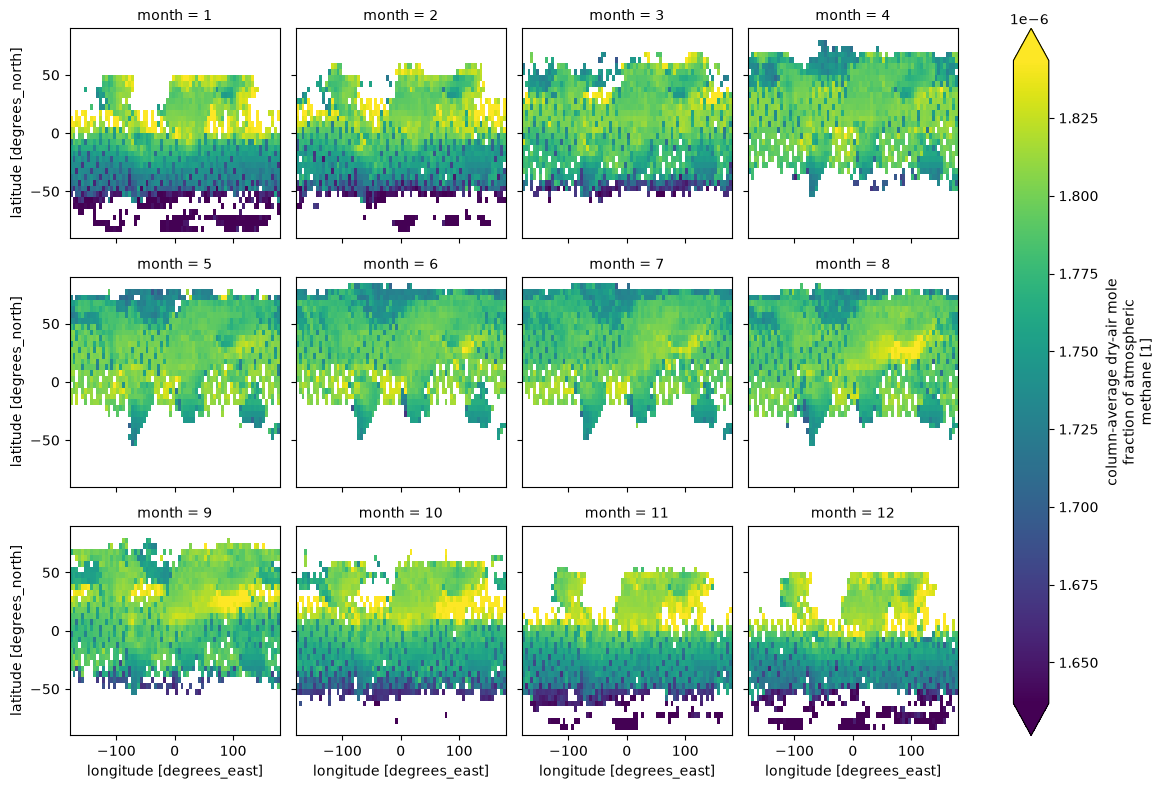

In [13]:
#1.1 Compute methane climatology for each month, and plot your results in 12 panels.
#先剔除甲烷数据的0、缺失值与极大值---按月进行分组并求平均---用xarray绘图
netCDF4['xch4']=netCDF4['xch4'].where((netCDF4['xch4'] > 0)&(netCDF4['xch4']<10000))
x1=netCDF4['xch4'].groupby('time.month').mean()
x1.plot(col='month', col_wrap=4, robust=True, figsize=(12, 8))
plt.show()

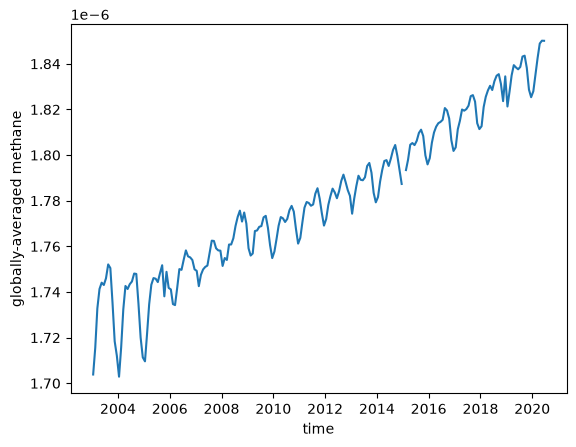

In [14]:
#1.2 Plot globally-averaged methane from 2003-01 to 2020-06 as a time series. 
#把三维数据（时间、纬度、经度）中的纬度和经度求平均，得到只随时间变化的一维全球平均序列
x2=netCDF4['xch4'].mean(dim=['lat', 'lon']).plot()
plt.ylabel('globally-averaged methane')
plt.show()

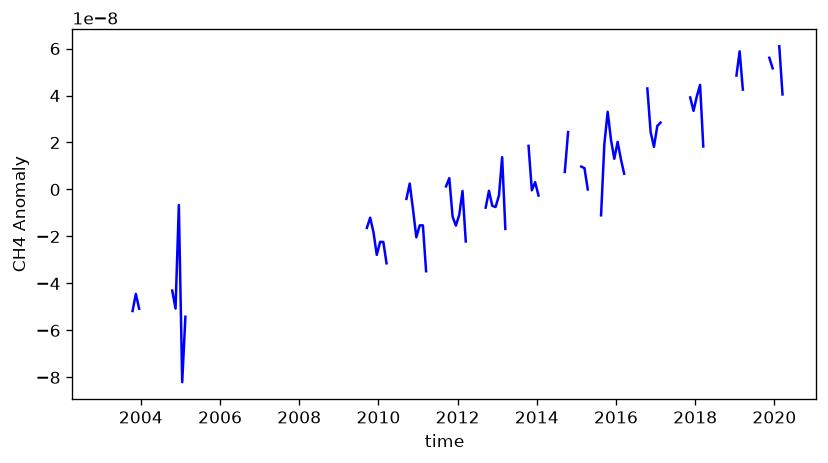

In [15]:
#1.3 lot deseasonalized methane levels at point [15°S, 150°W] from 2003-01 to 2020-06 as a time series. 
#提取该经纬度的数据，用该数据减去该点每个月的多年平均值，从而消除季节性的周期性波动
x3=netCDF4['xch4'].sel(lat=-15, lon=-150, method='nearest')#提取该点数据
x4=x3.groupby('time.month').mean(dim='time')#计算多年平均值
x5=x3.groupby('time.month')-x4

plt.figure(figsize=(8, 4), dpi=120)
x5.plot(color='b')
plt.ylabel('CH4 Anomaly') 
plt.show()

In [16]:
print(x4)#检查是否是缺失值

<xarray.DataArray 'xch4' (month: 12)> Size: 48B
array([1.7649329e-06, 1.7628456e-06, 1.7811150e-06, 1.7838219e-06,
                 nan,           nan, 1.8017327e-06, 1.7957475e-06,
       1.7686907e-06, 1.7560964e-06, 1.7638321e-06, 1.7671555e-06],
      dtype=float32)
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    lat      (month) float64 96B -12.5 -12.5 -12.5 -12.5 ... -12.5 -12.5 -12.5
    lon      (month) float64 96B -147.5 -147.5 -147.5 ... -147.5 -147.5 -147.5
Attributes:
    standard_name:  dry_atmosphere_mole_fraction_of_methane
    long_name:      column-average dry-air mole fraction of atmospheric methane
    units:          1
    cell_methods:   time: mean
    fill_value:     1e+20
    comment:        Satellite retrieved column-average dry-air mole fraction ...


In [3]:
#2. Niño 3.4 index
ds=xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc")
ds.head()

<xarray.Dataset> Size: 580B
Dimensions:  (time: 5, lat: 5, lon: 5)
Coordinates:
  * time     (time) datetime64[ns] 40B 1960-01-15 1960-02-15 ... 1960-05-15
  * lat      (lat) float32 20B -88.0 -86.0 -84.0 -82.0 -80.0
  * lon      (lon) float32 20B 0.0 2.0 4.0 6.0 8.0
Data variables:
    sst      (time, lat, lon) float32 500B ...
Attributes:
    Conventions:  IRIDL
    source:       https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/...
    history:      extracted and cleaned by Ryan Abernathey for Research Compu...

In [10]:
#2.1 Compute monthly climatology for SST from Niño 3.4 region, and subtract climatology from SST time series to obtain anomalies.
#提取赤道太平洋附近的数据，计算每个月的多年气候态，再用原始数据减去气候态得到异常值，再求赤道太平洋地区的平均，得到一维数据
SST=ds['sst'].sel(lat=slice(-5,5),lon=slice(190,240))
s1=SST.groupby('time.month').mean(dim='time')
s2=SST.groupby('time.month')-s1
Niño34Index=s2.mean(dim=['lat','lon'])
print(Niño34Index)

<xarray.DataArray 'sst' (time: 684)> Size: 3kB
array([-3.1957984e-01, -4.6852136e-01, -2.6815218e-01, -1.8696745e-01,
       -1.7759636e-01, -3.5768992e-01, -1.4197068e-01,  1.4657872e-02,
       -1.5222043e-01, -3.7986514e-01, -3.6089247e-01, -2.0869622e-01,
       -1.9147430e-01, -1.3428515e-01, -2.4037480e-01, -1.8512812e-01,
        5.1916372e-02,  2.3938322e-01, -7.0339397e-02, -4.1869378e-01,
       -7.7831775e-01, -7.9238480e-01, -4.9628872e-01, -4.1730934e-01,
       -4.4478282e-01, -4.5594049e-01, -4.3603396e-01, -4.6692902e-01,
       -5.6453085e-01, -4.2688489e-01, -2.7672547e-01, -3.1720972e-01,
       -6.7316109e-01, -6.6611850e-01, -8.1770629e-01, -8.6548859e-01,
       -7.0140064e-01, -3.5703859e-01,  6.9625296e-02,  1.7339660e-01,
       -9.0669163e-02,  7.6916955e-02,  6.8764049e-01,  7.9526329e-01,
        7.1297574e-01,  8.3424962e-01,  9.0853900e-01,  1.0858847e+00,
        8.5155445e-01,  5.2339661e-01, -1.3054201e-01, -6.3436538e-01,
       -8.6198235e-01, -9.4594

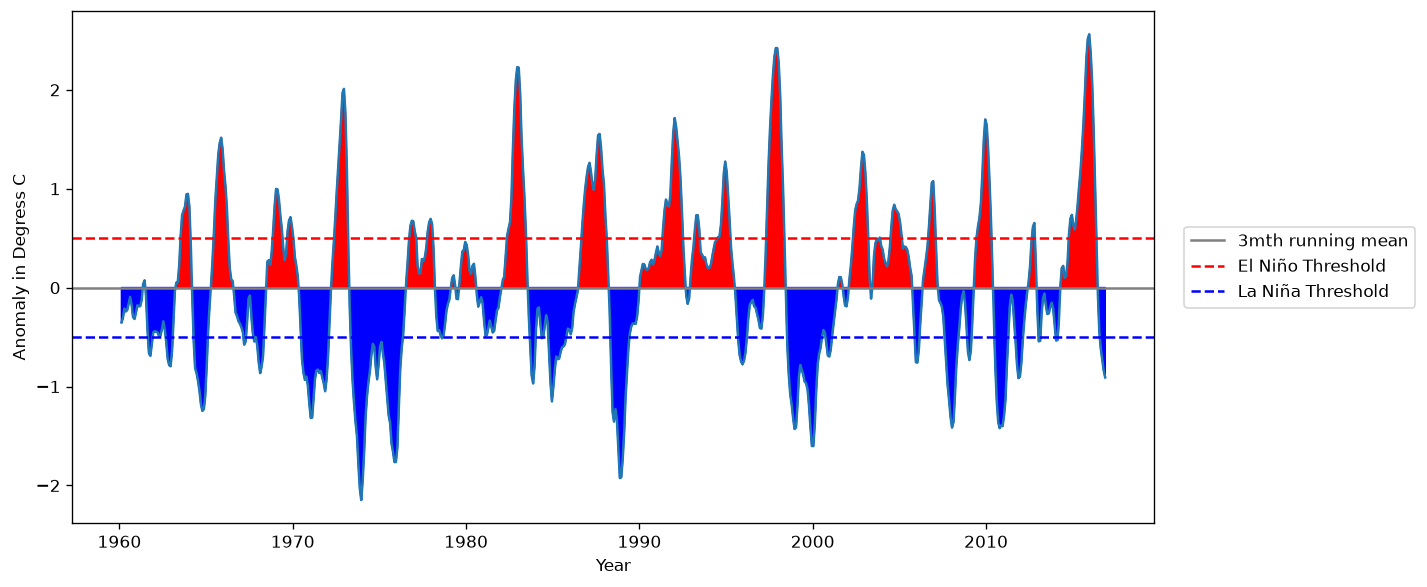

In [24]:
#2.2  Visualize the computed Niño 3.4.

# 学习使用rolling().mean()计算3个月的滑动平均
nino=Niño34Index.rolling(time=3, center=True).mean()
plt.figure(figsize=(12, 5), dpi=120)
plt.plot(nino['time'],nino)

plt.axhline(0, color='gray', linestyle='-', label='3mth running mean')
plt.axhline(0.5, color='red', linestyle='--', label='El Niño Threshold')
plt.axhline(-0.5, color='blue', linestyle='--', label='La Niña Threshold')

plt.fill_between(nino['time'],nino,0, where=(nino>=0),color='red')
plt.fill_between(nino['time'],nino,0, where=(nino<0),color='blue')
plt.ylabel('Anomaly in Degress C')
plt.xlabel('Year')
plt.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True)
plt.tight_layout()
plt.show()

In [2]:
#3. Explore a netCDF dataset

ds1= xr.open_dataset("tco_epic_monthly_v1_jan2015_to_dec2024_1by1.nc")
time_datetime = pd.to_datetime(ds1['Time'], format='%b%Y')
ds1 = ds1.assign_coords(Time=time_datetime)
ds1.head()

<xarray.Dataset> Size: 580B
Dimensions:    (Time: 5, Latitude: 5, Longitude: 5)
Coordinates:
  * Time       (Time) datetime64[us] 40B 2015-01-01 2015-02-01 ... 2015-05-01
  * Latitude   (Latitude) float32 20B -89.5 -88.5 -87.5 -86.5 -85.5
  * Longitude  (Longitude) float32 20B -179.5 -178.5 -177.5 -176.5 -175.5
Data variables:
    TropoO3    (Time, Latitude, Longitude) float32 500B ...

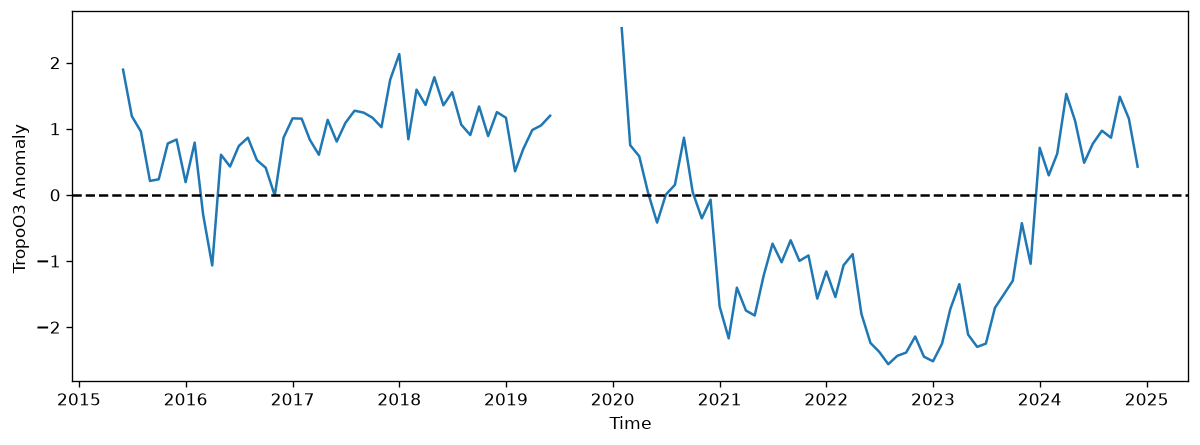

In [24]:
#3.1
# 先用.where()剔除小于等于0的值和极大的异常值，进而计算全球平均时间序列，最后再进行计算逐月的气候态并去季节化

ds1['TropoO3']=ds1['TropoO3'].where((ds1['TropoO3']>0) & (ds1['TropoO3']<10000))
g1= ds1['TropoO3'].mean(dim=['Latitude', 'Longitude'])
g2=g1.groupby('Time.month').mean(dim='Time')
g3=g1.groupby('Time.month')-g2

plt.figure(figsize=(12, 4), dpi=120)
g3.plot()
plt.axhline(0, color='black', linestyle='--')
plt.ylabel('TropoO3 Anomaly ')
plt.show()

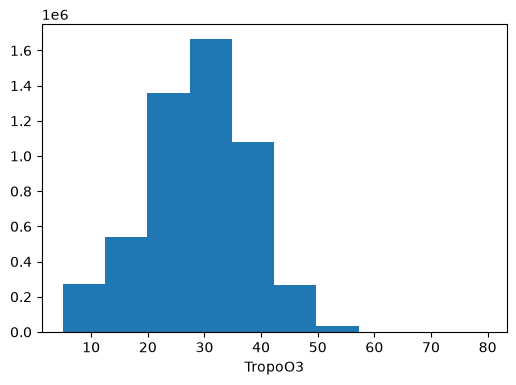

In [27]:
#3.2.1 直方图

plt.figure(figsize=(6, 4), dpi=100)
ds1['TropoO3'].plot.hist()
plt.xlabel('TropoO3')
plt.show()

<Figure size 1000x600 with 0 Axes>

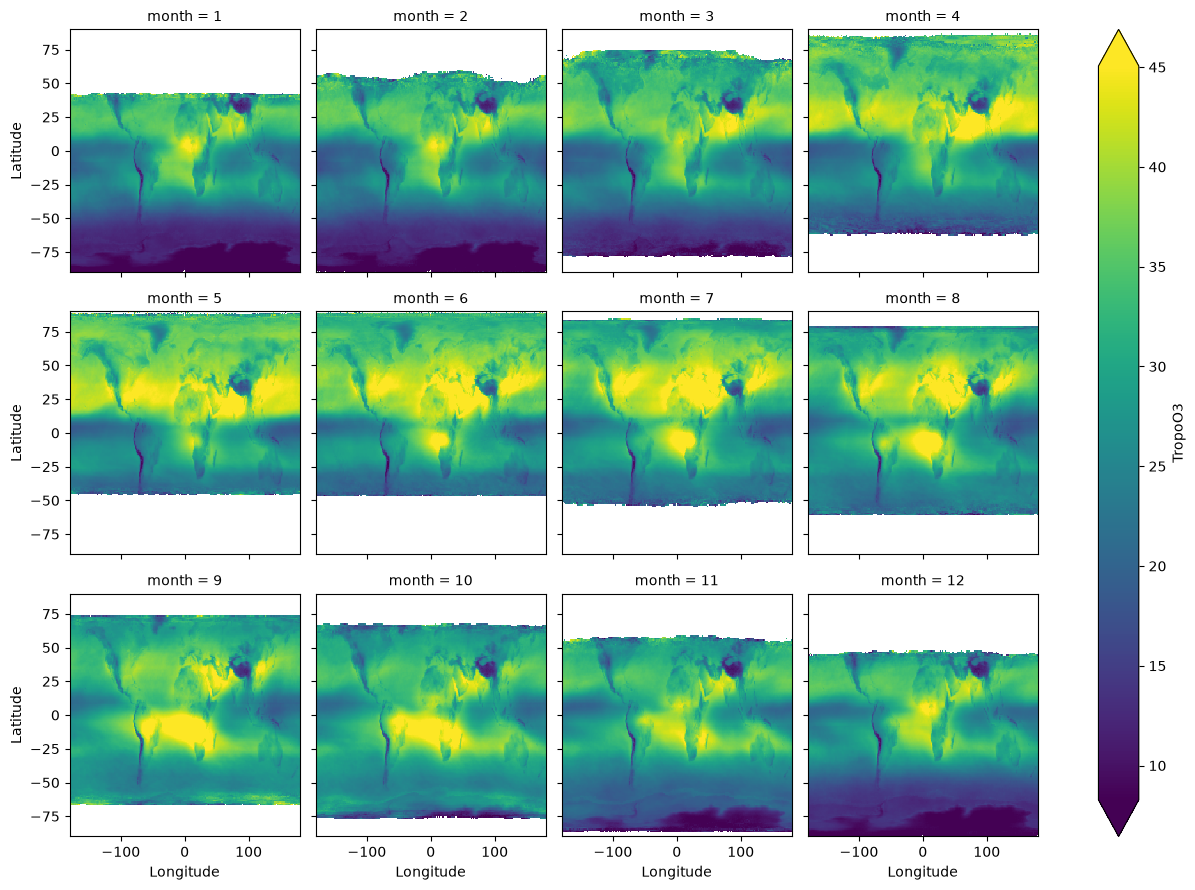

In [25]:
#3.2.2 12个月的多年平均浓度

plt.figure(figsize=(10, 6), dpi=100)
ds1['TropoO3'].groupby('Time.month').mean(dim='Time') .plot(col='month', col_wrap=4, robust=True)
plt.show()

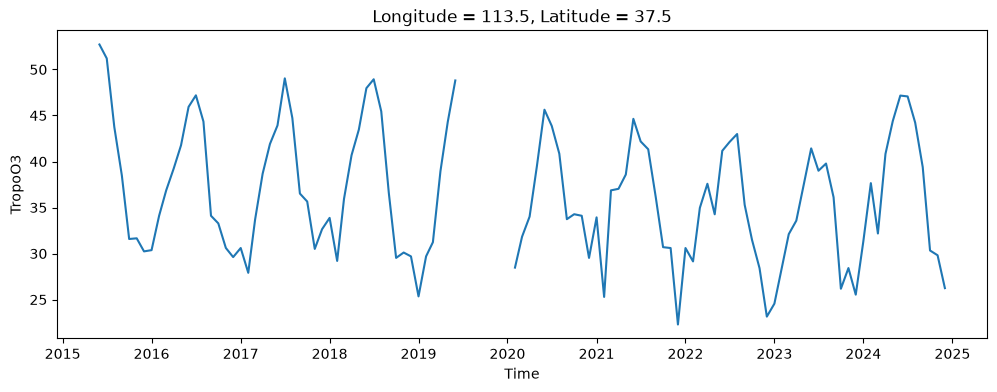

In [35]:
#3.2.3特定地点的d十年时间序列
plt.figure(figsize=(12, 4))
# 用.sel()选取家乡附近的经纬度数据，method='nearest'寻找最接近的网格点，绘制出该点十年的TropoO3浓度
ds1['TropoO3'].sel(Latitude=37, Longitude=113, method='nearest').plot()
plt.ylabel('TropoO3')
plt.show()

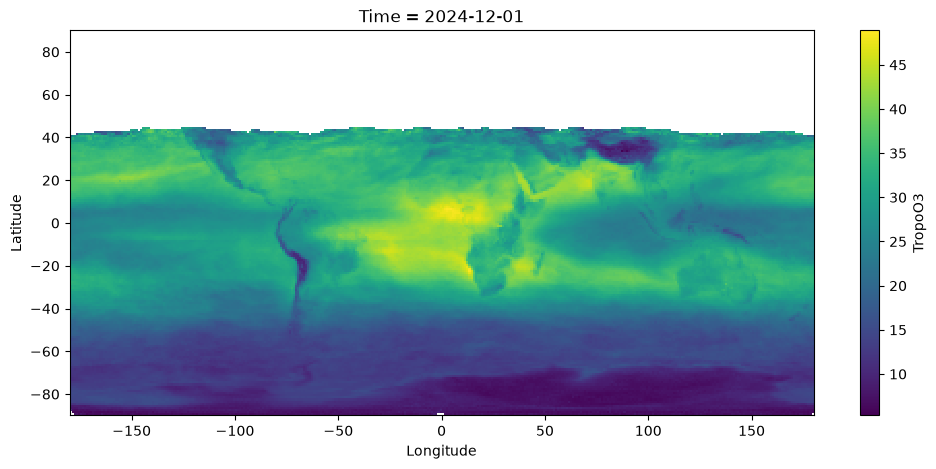

In [31]:
#3.2.4 某一时间的空间分布图
plt.figure(figsize=(12, 5))
#使用 isel(Time=-1) 选取最后一个时间点
ds1['TropoO3'].isel(Time=-1).plot()
plt.show()

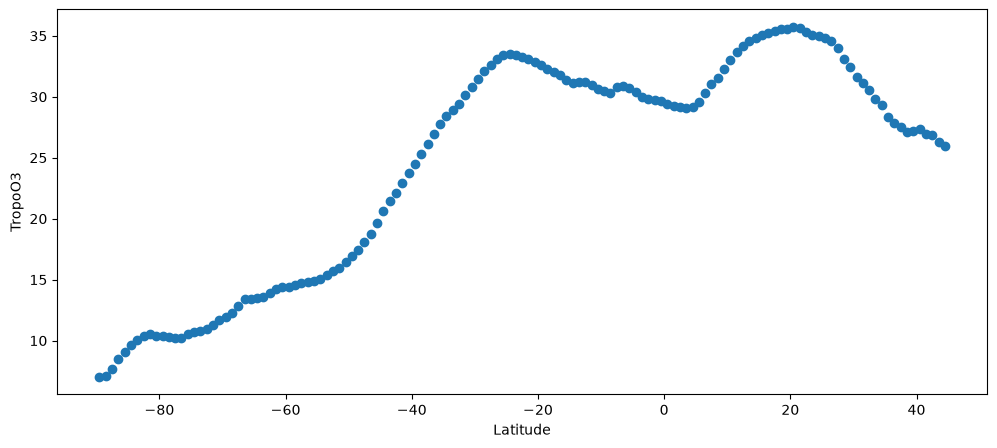

In [34]:
#3.2.5 散点图
plt.figure(figsize=(12, 5))
# 提取特定时间的数据，并对经度求平均，剩下一维的纬度和臭氧浓度
lat1 = ds1['TropoO3'].isel(Time=-1).mean(dim='Longitude')
plt.scatter(ds1['Latitude'], lat1)
plt.xlabel('Latitude')
plt.ylabel('TropoO3')
plt.show()